**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**19 | Subject-Disjoint Temperature Calibration**

![Stage 19 scientific workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/19_workflow.svg)

**Objective:** Evaluate scalar temperature scaling for a weighted CNN using separate Train, Calibration and Validation participants within each Development fold.

**Dataset:** The 29-participant HARTH v2.0 Development cohort, excluding reserved Test identities S023 and S032.

**Notebook Scope:** Fit CNN preprocessing and weights on Train only, estimate temperature using Calibration labels and evaluate probability metrics on disjoint outer Validation participants. These results describe Development calibration, not independent final Test or clinical uncertainty validation.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Reusable Calibration Functions**

In [ ]:
# ============== 01. Imports and Reusable Calibration Functions ===============

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display

# -------- 4. Machine Learning, Deep Learning and Evaluation Utilities --------
import torch
from sklearn.model_selection import GroupKFold

# ------------------ 5. HARTH and Shared Research Utilities -------------------
from harth_data import HARTH_SUBJECTS,prepare_harth_nested_window_cohort
from core.temporal_cnn import train_temporal_cnn_fixed_steps,predict_temporal_cnn_probabilities
from core.temperature_calibration import fit_temperature,apply_temperature,multiclass_nll
from core.prediction_reliability import audit_prediction_confidence

# ------------------------- 6. Scientific Plot Style --------------------------
from core.plot_style import plot_style
plot_style()

# ----------------------- 7. Training Device Selection ------------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type


Compute device and system information
OS: Linux 6.6.122+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu128
CUDA device: Tesla T4
CUDA runtime: 12.8
cuDNN version: 91900
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda


**02. Construct Development Data and Outer Participant Folds**

Build three outer subject-disjoint Development folds from the previously defined nested cohort. Reserve outer Validation participants before creating inner Train and Calibration groups. S023 and S032 are not loaded.

In [ ]:
# ======== 02. Construct Development Data and Outer Participant Folds =========

# ------------- 1. Prepare Development and Reserved Test Cohorts --------------
RESERVED_TEST={"S023","S032"}
SUBJECTS=sorted(set(HARTH_SUBJECTS)-RESERVED_TEST)
CLASSES=tuple(range(1,9))
X,metadata,overview=prepare_harth_nested_window_cohort(
    SUBJECTS,root/"data/raw/harth_v2",task_classes=CLASSES,
    base_cap=500,expanded_cap=1000,  # Retain the original base cohort for outer Validation.
    window_size=100,step_size=50,sampling_rate=50
)

# -------------------- 2. Map Base Source Rows and Labels ---------------------
base=np.flatnonzero(metadata["in_base_500"].to_numpy(dtype=bool))
y=metadata["label"].to_numpy()
groups=metadata["subject_id"].to_numpy()
assert len(SUBJECTS)==29 and len(base)==14201
assert not(set(groups)&RESERVED_TEST)
folds=list(GroupKFold(n_splits=3).split(
    np.zeros(len(base)),y[base],groups=groups[base]))

print("Prepared",len(base),"base Validation candidates and",len(X),"expanded windows")


Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Downloaded 50,898,931 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 sa

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Reje

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Prepared 14201 base Validation candidates and 28201 expanded windows


**03. Separate Train, Calibration and Validation Participants**

Within each outer fold, allocate approximately 80% of the remaining participants to Train and 20% to Calibration. CNN scaling and class weights are fitted on Train; temperature uses Calibration labels only. Outer Validation participants have no overlap with either group.

In [4]:
# ======== 03. Separate Train, Calibration and Validation Participants ========

# ---------------- 1. Split Train, Calibration and Validation -----------------
from sklearn.model_selection import GroupShuffleSplit
device="cuda" if torch.cuda.is_available() else "cpu"
oof_records=[]
fold_records=[]

# -------------------- 2. Fit and Calibrate Nested Models ---------------------
for fold,(outer_train,outer_valid) in enumerate(folds,start=1):
    outer_train_rows=base[outer_train]
    validation_rows=base[outer_valid]
    inner=GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42+fold)
    inner_train,inner_cal=next(inner.split(
        np.zeros(len(outer_train_rows)),y[outer_train_rows],groups[outer_train_rows]))
    train_people=set(groups[outer_train_rows[inner_train]])
    cal_people=set(groups[outer_train_rows[inner_cal]])
    valid_people=set(groups[validation_rows])
    assert not(train_people&cal_people or train_people&valid_people or cal_people&valid_people)
    train_rows=np.flatnonzero(np.isin(groups,list(train_people)))
    cal_rows=outer_train_rows[inner_cal]  # Original 500-cap Calibration rows only
    assert set(CLASSES).issubset(set(y[train_rows]))
    print(f"Fold {fold}: Train={len(train_people)}, Calibration={len(cal_people)}, Validation={len(valid_people)} subjects")
    model,history,_,stats=train_temporal_cnn_fixed_steps(
        X[train_rows],y[train_rows],X[cal_rows],y[cal_rows],
        classes=CLASSES,max_steps=400,eval_every=400,batch_size=128,
        learning_rate=1e-3,seed=42,device=device,class_weighting="inverse_sqrt")
    cal_prob=predict_temporal_cnn_probabilities(model,X[cal_rows],stats,CLASSES,device=device)
    temp_fit=fit_temperature(cal_prob,y[cal_rows],CLASSES)
    raw=predict_temporal_cnn_probabilities(model,X[validation_rows],stats,CLASSES,device=device)
    scaled=apply_temperature(raw,temp_fit["temperature"])
    for name,p in [("Uncalibrated",raw),("Temperature scaled",scaled)]:
        _,bins,_,metrics=audit_prediction_confidence(
            y[validation_rows],p,groups[validation_rows],CLASSES)
        fold_records.append({
            "fold":fold,"method":name,"temperature":temp_fit["temperature"],
            "train_subjects":len(train_people),"calibration_subjects":len(cal_people),
            "validation_subjects":len(valid_people),"validation_windows":len(validation_rows),
            "nll":multiclass_nll(y[validation_rows],p,CLASSES),
            "ece":metrics["ece_10_bins"],"brier":metrics["multiclass_brier"],
            "accuracy":metrics["accuracy"]})
        oof_records.append(pd.DataFrame({
            "fold":fold,"method":name,"source_row":validation_rows,
            "subject_id":groups[validation_rows],"true_label":y[validation_rows],
            **{f"prob_{code}":p[:,i] for i,code in enumerate(CLASSES)}
        }))

# ------------------ 3. Record Fold Metrics and Predictions -------------------
fold_results=pd.DataFrame(fold_records)
oof=pd.concat(oof_records,ignore_index=True)
display(fold_results.round(4))


Fold 1: Train=15, Calibration=4, Validation=10 subjects
Step 400/400 | loss=0.4655 | Validation Macro F1=0.7452
Fold 2: Train=15, Calibration=4, Validation=10 subjects
Step 400/400 | loss=0.4938 | Validation Macro F1=0.8272
Fold 3: Train=16, Calibration=4, Validation=9 subjects
Step 400/400 | loss=0.4890 | Validation Macro F1=0.7707


,fold,method,temperature,train_subjects,calibration_subjects,validation_subjects,validation_windows,nll,ece,brier,accuracy
0,1,Uncalibrated,0.6297,15,4,10,5000,0.3319,0.0349,0.1475,0.8894
1,1,Temperature scaled,0.6297,15,4,10,5000,0.3853,0.0471,0.1524,0.8894
2,2,Uncalibrated,0.3970,15,4,10,4701,0.2197,0.0723,0.0940,0.9475
3,2,Temperature scaled,0.3970,15,4,10,4701,0.1998,0.0162,0.0791,0.9475
4,3,Uncalibrated,0.5051,16,4,9,4500,0.1988,0.0420,0.0850,0.9444
5,3,Temperature scaled,0.5051,16,4,9,4500,0.1909,0.0224,0.0825,0.9444


**04. Compare Probability Metrics by Fold**

Compare negative log-likelihood (NLL), expected calibration error (ECE), multiclass Brier score and accuracy before and after temperature scaling. The recorded fold means show lower ECE and Brier scores after calibration, but higher NLL, while classification accuracy remains unchanged. One fold worsened on all three probability metrics. ECE is also sensitive to the binning scheme.

nll                             ece               \
method Temperature scaled Uncalibrated Temperature scaled Uncalibrated   
fold                                                                     
1                  0.3853       0.3319             0.0471       0.0349   
2                  0.1998       0.2197             0.0162       0.0723   
3                  0.1909       0.1988             0.0224       0.0420   

                    brier                        accuracy               
method Temperature scaled Uncalibrated Temperature scaled Uncalibrated  
fold                                                                    
1                  0.1524       0.1475             0.8894       0.8894  
2                  0.0791       0.0940             0.9475       0.9475  
3                  0.0825       0.0850             0.9444       0.9444

,nll,ece,brier,accuracy
method,,,,
Temperature scaled,0.2587,0.0286,0.1047,0.9271
Uncalibrated,0.2502,0.0497,0.1088,0.9271


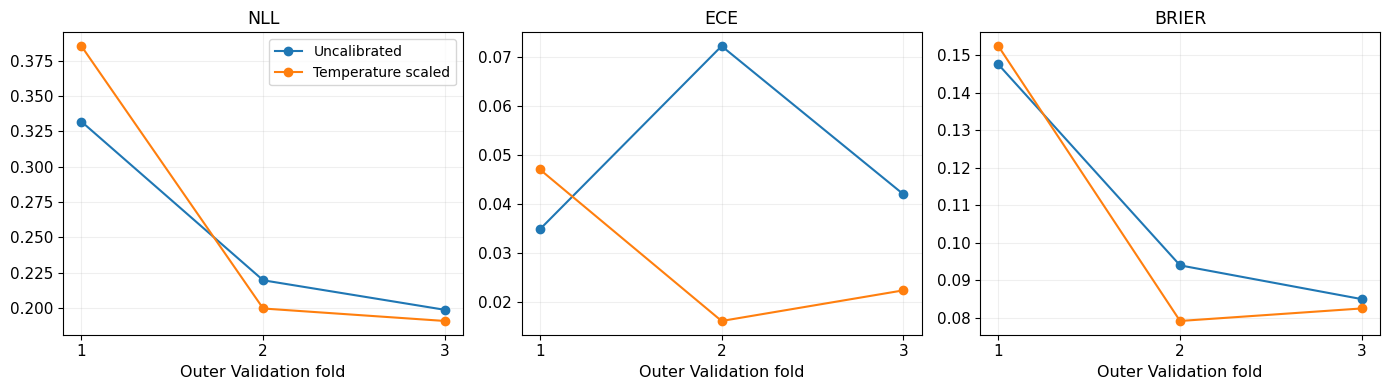

In [5]:
# ================== 04. Compare Probability Metrics by Fold ==================

# ------------------ 1. Compare Per-Fold Calibration Results ------------------
comparison=fold_results.pivot(index="fold",columns="method",values=["nll","ece","brier","accuracy"])
display(comparison.round(4))
means=fold_results.groupby("method")[["nll","ece","brier","accuracy"]].mean()
display(means.round(4))

# --------------------- 2. Visualise Probability Metrics ----------------------
fig,axes=plt.subplots(1,3,figsize=(14,4))

for ax,metric in zip(axes,["nll","ece","brier"]):
    for name,frame in fold_results.groupby("method",sort=False):
        ax.plot(frame["fold"],frame[metric],marker="o",label=name)
    ax.set(title=metric.upper(),xlabel="Outer Validation fold",xticks=[1,2,3])
    ax.grid(alpha=0.2)

axes[0].legend()
fig.tight_layout()
plt.show()


**05. Inspect Out-of-Fold Reliability**

Evaluate the two probability conditions on the same 14,201 base-window source rows, held out once per outer fold. Reliability plots are descriptive because windows overlap within participant recordings.

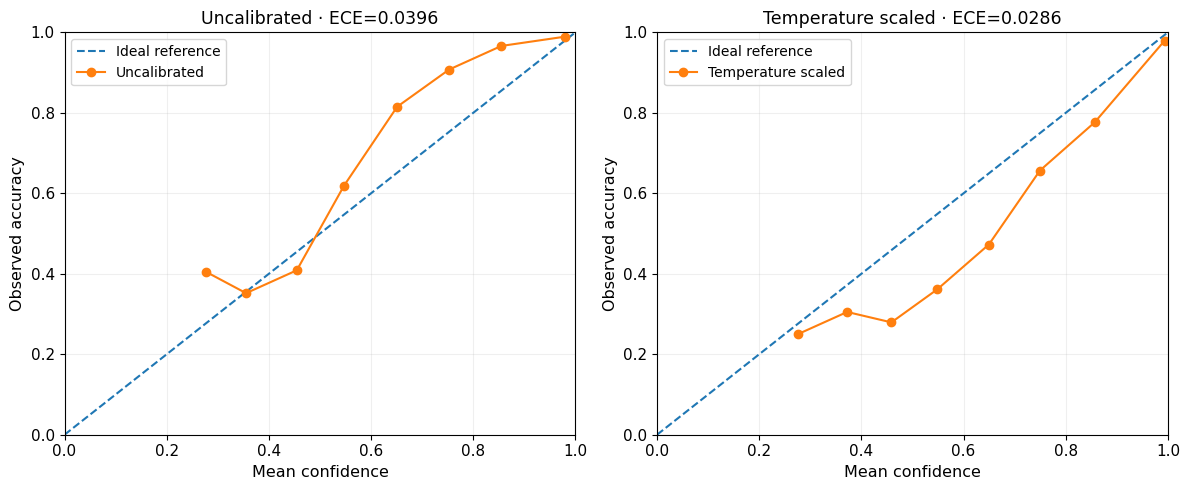

In [6]:
# ==================== 05. Inspect Out-of-Fold Reliability ====================
fig,axes=plt.subplots(1,2,figsize=(12,5))

for ax,(name,table) in zip(axes,oof.groupby("method",sort=False)):
    table=table.sort_values("source_row")
    probabilities=table[[f"prob_{c}" for c in CLASSES]].to_numpy()
    _,bins,_,metrics=audit_prediction_confidence(
        table["true_label"].to_numpy(),probabilities,
        table["subject_id"].to_numpy(),CLASSES)
    selected=bins[bins["windows"]>0]
    ax.plot([0,1],[0,1],"--",label="Ideal reference")
    ax.plot(selected["mean_confidence"],selected["observed_accuracy"],
            marker="o",label=name)
    ax.set(xlim=(0,1),ylim=(0,1),title=f"{name} · ECE={metrics['ece_10_bins']:.4f}",
           xlabel="Mean confidence",ylabel="Observed accuracy")
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


**06. Scientific Quality Gate and Calibration Limitations**

Verify disjoint Train, Calibration and Validation identities, positive fitted temperatures and protected Test exclusion. Positive scalar temperature leaves top-1 predictions unchanged, apart from numerical edge cases. These Development results do not establish external calibration or clinical reliability.

In [7]:
# ========== 06. Scientific Quality Gate and Calibration Limitations ==========

# ------------------ 1. Verify Source Rows and Probabilities ------------------
original_rows=set(base.tolist())

for name,part in oof.groupby("method"):
    assert len(part)==len(base)
    assert part["source_row"].is_unique
    assert set(part["source_row"])==original_rows
    assert not(set(part["subject_id"])&RESERVED_TEST)
uncal=oof[oof["method"]=="Uncalibrated"].sort_values("source_row")
cal=oof[oof["method"]=="Temperature scaled"].sort_values("source_row")
raw_p=uncal[[f"prob_{c}" for c in CLASSES]].to_numpy()
new_p=cal[[f"prob_{c}" for c in CLASSES]].to_numpy()

# ----------------- 2. Check Class and Temperature Integrity ------------------
np.testing.assert_array_equal(raw_p.argmax(axis=1),new_p.argmax(axis=1))
assert len(fold_results)==6
assert fold_results["temperature"].gt(0).all()

# ------------------ 3. Quality Gate and Calibration Limits -------------------
print("Participant-disjoint calibration and outer Validation: PASSED")
print("Original Test data loaded or scored: NO")
print("Independent final calibration/generalisation: NOT ESTABLISHED")


Participant-disjoint calibration and outer Validation: PASSED
Original Test data loaded or scored: NO
Independent final calibration/generalisation: NOT ESTABLISHED
